In [1]:
import numpy as np
import matplotlib.pyplot as plt

# The Python implementation of the function above is rather slow
# We made a C++ library that implements the function above much faster
# To run this library one needs to load cpp_routines which will, in turn, 
# load a library routines_lib.so from the folder RewardCalc
# If the library file is not there the loader will attempt to run Makefile in RewardCalc
# The library function expected_reward_table is called in exactly the same way

import sys
sys.path.append('../Simulations')
sys.path.append('../Calculations')
from cpp_routines import *
from data_process import *

In [2]:
# We have coded up a special C++ function that finds the minimal number of remaining presses
# For which it is more optimal to leave the current button and explore further
# For given number of wins and fails
# If no such number exists for the given process duration, the function returns 0

trans_table = optimal_transition_table(10, 10, 2000, prior=(1, 1))
print(trans_table)

[[   1    1    1    1    1    1    1    1    1    1]
 [   0    1    1    1    1    1    1    1    1    1]
 [   0   12    1    1    1    1    1    1    1    1]
 [   0   39    5    1    1    1    1    1    1    1]
 [   0   94   10    3    1    1    1    1    1    1]
 [   0  190   19    6    3    1    1    1    1    1]
 [   0  344   30   10    5    2    1    1    1    1]
 [   0  578   45   14    7    4    2    1    1    1]
 [   0  915   63   20    9    5    3    2    1    1]
 [   0 1385   86   27   13    7    5    3    2    1]]


In [3]:
run_time = 100
number_of_runs = 10000
# button = Button('Bernoulli', prior=(1, 1))
button = Button('Truncated', truncation=0.9)
policy = Policy('Bernoulli', prior=(1, 1))
# policy = Policy('Truncated', truncation=0.9)
# policy = Policy('Difference', difference=4)

trial_record = record_full_trials(run_time, number_of_runs, button, policy)

In [4]:
process = Decision_Process(trial_record)

In [5]:
out1, out2 = np.unique(process.decisions[:,:2], axis=0, return_counts=True)
total_counts = np.c_[out1, out2]

In [6]:
total_counts[total_counts[:,0]<10]

array([[     0,      1, 100899],
       [     1,      0,  82634],
       [     1,      1,  33032],
       [     2,      0,  49542],
       [     2,      1,  16300],
       [     2,      2,    140],
       [     3,      0,  33194],
       [     3,      1,   9481],
       [     3,      2,    604],
       [     3,      3,     11],
       [     4,      0,  23835],
       [     4,      1,   6983],
       [     4,      2,   2047],
       [     4,      3,     30],
       [     4,      4,      1],
       [     5,      0,  17867],
       [     5,      1,   8491],
       [     5,      2,   2487],
       [     5,      3,     89],
       [     5,      4,     11],
       [     5,      5,      1],
       [     6,      0,  13753],
       [     6,      1,   8880],
       [     6,      2,   2461],
       [     6,      3,    150],
       [     6,      4,     19],
       [     6,      5,      4],
       [     7,      0,  10901],
       [     7,      1,   8721],
       [     7,      2,   2451],
       [  

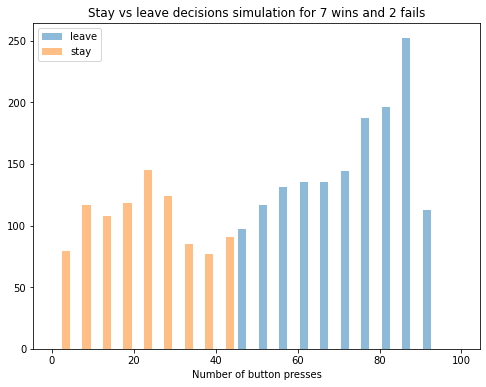

In [7]:
wins, fails = 7, 2
choise = process.decisions[np.logical_and(process.decisions[:,0]==wins, process.decisions[:,1]==fails)][:,2:]
leave = choise[choise[:,0]==1][:,1]
stay = choise[choise[:,0]==0][:,1]

plt.figure(figsize=(8,6))
plt.hist([leave, stay], alpha=0.5, label=["leave", "stay"], range=[0.0, 100.0], bins=20)
plt.legend(loc="upper left")
plt.xlabel("Number of button presses")
plt.title("Stay vs leave decisions simulation for 7 wins and 2 fails")
plt.savefig('wins_7_loose_2_simulation.png',dpi=120)
plt.show()

The average number of buttons explored is 18.3654
The average reward received is 72.1676
Out of 10000 subjects in total 8727 subjects (or 87.27%) got the largest contribution from the last button
The average contribution of the button with the largest contribution is 66.82 %


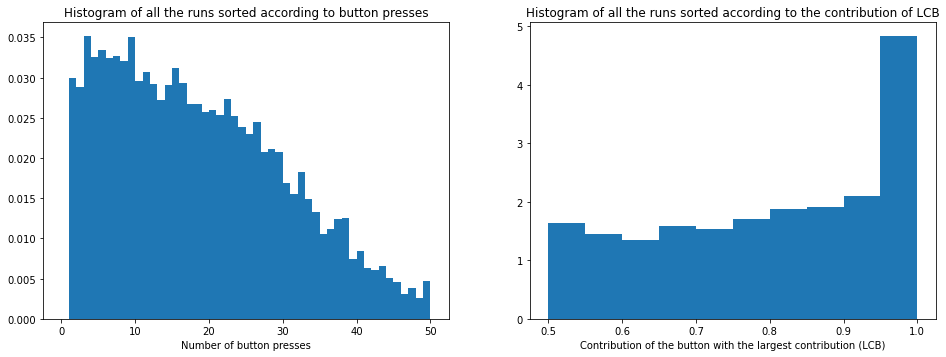

In [8]:
num_buttons, top_button_to_all = process.analyze_largest_contribution()

fig = plt.figure(figsize=(16,12))
ax = fig.add_subplot(221)
ax.set_title("Histogram of all the runs sorted according to button presses")
ax.set_xlabel("Number of button presses")
ax.hist(num_buttons, density=True, bins=50, range=(0, 50));

ax = fig.add_subplot(222)
ax.set_title("Histogram of all the runs sorted according to the contribution of LCB")
ax.set_xlabel("Contribution of the button with the largest contribution (LCB)")
ax.hist(top_button_to_all, density=True, bins=10, range=(0.5,1));

Total number of stay decisions is 532892
Total number of leave decisions is 173654


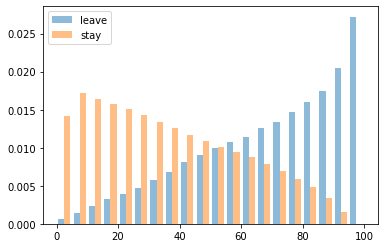

In [9]:
select = process.get_decisions(discard_no_fails=True, wins_more_fails=False)
select_stay = select[select[:,2] == 0]
select_leave = select[select[:,2] == 1]

print("Total number of stay decisions is " + str(len(select_stay)))
print("Total number of leave decisions is " + str(len(select_leave)))

plt.hist([select_leave[:,3], select_stay[:,3]], alpha=0.5, label=["leave", "stay"], range=[0.0, 100.0], bins=20, density=True)
plt.legend(loc="upper left")
plt.show()

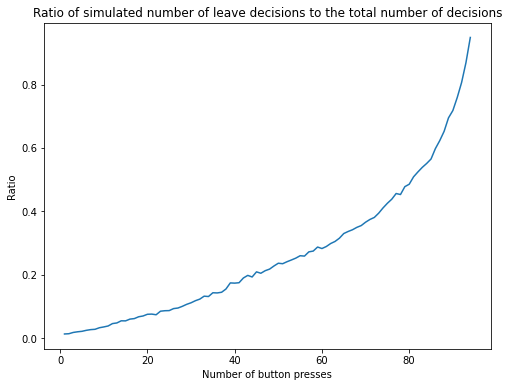

In [10]:
aggregate = aggregate_wins_fails(process.get_decisions(wins_more_fails=False))

plt.figure(figsize=(8,6))
plt.title("Ratio of simulated number of leave decisions to the total number of decisions")
plt.xlabel("Number of button presses")
plt.ylabel("Ratio")
plt.plot(aggregate[:,0],aggregate[:,1]/(aggregate[:,1]+aggregate[:,2]))
plt.savefig('ratio_simulation_all.png',dpi=120)
plt.show()

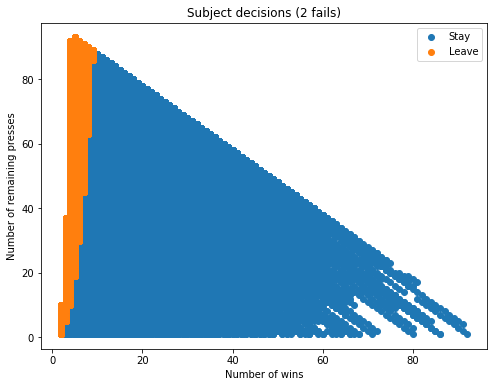

In [11]:
fails = 2
select_fail = process.decisions[process.decisions[:,1] == fails]
sf_stay = select_fail[select_fail[:,2]==0][:,[0,3]]
sf_leave = select_fail[select_fail[:,2]==1][:,[0,3]]

plt.figure(figsize=(8,6))
plt.xlabel("Number of wins")
plt.ylabel("Number of remaining presses")
plt.title("Subject decisions (" + str(fails) + " fails)")
# plt.xlim(0,15)
# plt.ylim(0,100)
plt.scatter(sf_stay[:,0], sf_stay[:,1], c='C0', label="Stay")
plt.scatter(sf_leave[:,0], sf_leave[:,1], c='C1', label="Leave")
plt.legend(loc="upper right")
plt.show()